# Ejercicio 13. Accesos en orden a un splay tree que empieza como un camino

Este cuaderno acompaña al informe [`ejercicio-13.md`](ejercicio-13.md). Ejecuta el
código del splay de la conferencia 4 (sección 4), comprueba el lema de acceso y la
identidad de la suma amortizada en cada acceso, mide el costo de recorrer las claves
en orden y lo compara con la cota. Genera `ejercicio-13.png`. Las secciones siguen la
numeración del informe.

El costo es el de la conferencia: rotaciones, y 1 cuando el nodo ya es la raíz.
Para reproducirlo hacen falta Python 3, `matplotlib` e `IPython`.

In [1]:
import math
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
from IPython.display import Image, display

## 1. Formulación

El código de `Nodo`, `rotar`, `splay`, `buscar` y `camino` es el de la conferencia 4.
`camino(n)` es el árbol inicial: $n$ en la raíz y cada clave hija izquierda de la
siguiente. Las funciones de potencial son iterativas, para no depender del límite de
recursión con $n$ grande. Las recursivas de la conferencia se incluyen más abajo y se comprueba que dan el mismo
valor: $\Phi=\sum_x\log_2 s(x)$.

In [2]:
class Nodo:
    def __init__(self, clave):
        self.clave, self.izq, self.der, self.padre = clave, None, None, None


def rotar(x):
    """Sube x un nivel rotando la arista con su padre. Preserva el orden."""
    p, g = x.padre, x.padre.padre
    if p.izq is x:
        p.izq, x.der = x.der, p
        if p.izq:
            p.izq.padre = p
    else:
        p.der, x.izq = x.izq, p
        if p.der:
            p.der.padre = p
    p.padre, x.padre = x, g
    if g:
        if g.izq is p:
            g.izq = x
        else:
            g.der = x


def splay(x):
    rotaciones = 0
    while x.padre:
        p, g = x.padre, x.padre.padre
        if g is None:                                   # zig
            rotar(x)
            rotaciones += 1
        elif (g.izq is p) == (p.izq is x):              # zig-zig: primero el padre
            rotar(p)
            rotar(x)
            rotaciones += 2
        else:                                           # zig-zag
            rotar(x)
            rotar(x)
            rotaciones += 2
    return rotaciones


def buscar(raiz, clave):
    x = raiz
    while x.clave != clave:
        x = x.izq if clave < x.clave else x.der
    return x


def camino(n):
    """El peor árbol inicial: n en la raíz, cada clave hija izquierda de la siguiente."""
    nodos = [Nodo(k) for k in range(1, n + 1)]
    for k in range(1, n):
        nodos[k].izq, nodos[k - 1].padre = nodos[k - 1], nodos[k]
    return nodos[-1]


def tamanos(raiz):
    orden, pila = [], [raiz]
    while pila:
        v = pila.pop()
        orden.append(v)
        pila.extend(h for h in (v.izq, v.der) if h)
    s = {}
    for v in reversed(orden):
        s[v] = 1 + (s[v.izq] if v.izq else 0) + (s[v.der] if v.der else 0)
    return s


def potencial(raiz):
    return sum(math.log2(t) for t in tamanos(raiz).values())


def forma(raiz):
    """La estructura completa: para cada clave, las claves de sus hijos."""
    pila, hijos = [raiz], {}
    while pila:
        v = pila.pop()
        hijos[v.clave] = (v.izq.clave if v.izq else None, v.der.clave if v.der else None)
        pila.extend(h for h in (v.izq, v.der) if h)
    return raiz.clave, hijos


def claves_en_orden(raiz):
    out, pila, v = [], [], raiz
    while pila or v:
        while v:
            pila.append(v)
            v = v.izq
        v = pila.pop()
        out.append(v.clave)
        v = v.der
    return out


def log2_factorial(n):
    return math.lgamma(n + 1) / math.log(2)

In [3]:
# el splay conserva el orden de búsqueda y los punteros al padre
rng = Random(13)
raiz = camino(50)
for _ in range(500):
    raiz = buscar(raiz, rng.randint(1, 50))
    splay(raiz)
assert claves_en_orden(raiz) == list(range(1, 51)) and raiz.padre is None
for v in tamanos(raiz):
    assert all(h.padre is v for h in (v.izq, v.der) if h)
for n in [1, 2, 7, 60]:
    assert abs(potencial(camino(n)) - log2_factorial(n)) < 1e-9
print("ok: splay conserva el orden; el potencial del camino es log2 n!")

ok: splay conserva el orden; el potencial del camino es log2 n!


Las funciones recursivas de la conferencia 4 (sección 5) se incluyen tal cual, con el
nombre `potencial_recursivo` para no chocar con la versión iterativa. Cada una recorre
el árbol con recursión de profundidad igual a la del árbol, así que solo se usan en
tamaños pequeños, para comprobar que ambas versiones dan el mismo valor.

In [4]:
def tamano_subarbol(x):
    return 0 if x is None else 1 + tamano_subarbol(x.izq) + tamano_subarbol(x.der)


def potencial_recursivo(x):
    if x is None:
        return 0.0
    return math.log2(tamano_subarbol(x)) + potencial_recursivo(x.izq) + potencial_recursivo(x.der)


rng = Random(131)
comparados = 0
for n in [1, 2, 7, 30, 100]:
    raiz = camino(n)
    for paso in range(40):
        assert abs(potencial(raiz) - potencial_recursivo(raiz)) < 1e-9
        assert all(tamanos(raiz)[v] == tamano_subarbol(v) for v in tamanos(raiz))
        comparados += 1
        raiz = buscar(raiz, rng.randint(1, n))
        splay(raiz)
print(f"ok: potencial iterativo y recursivo coinciden en {comparados} árboles")

ok: potencial iterativo y recursivo coinciden en 200 árboles


## 2. La cota del lema de acceso

Para $m$ accesos, la sección 5 de la conferencia da
$\sum c_i\le m(3\log_2n+1)+\Phi_0-\Phi_m$. Aquí $\Phi_0=\log_2n!$ y $\Phi_m\ge0$.
El cuaderno comprueba, **en cada acceso** de un recorrido en orden, el lema
$\hat c_i\le3(\log_2n-r(x_i))+1$ y la identidad
$\sum c_i=\sum\hat c_i+\Phi_0-\Phi_m$, con $c_i=\max(\text{rotaciones},1)$.

In [5]:
def cota_total(n, accesos):
    return accesos * (3 * math.log2(n) + 1) + log2_factorial(n)


def recorrido_vigilado(n):
    raiz = camino(n)
    phi0 = potencial(raiz)
    real = amortizado = suma_lema = 0.0
    phi = phi0
    for clave in range(1, n + 1):
        x = buscar(raiz, clave)
        r_x = math.log2(tamanos(raiz)[x])
        c = max(splay(x), 1)
        raiz = x
        nuevo = potencial(raiz)
        c_hat = c + nuevo - phi
        lema = 3 * (math.log2(n) - r_x) + 1
        assert c_hat <= lema + 1e-9
        real, amortizado, suma_lema, phi = real + c, amortizado + c_hat, suma_lema + lema, nuevo
    assert abs(real - (amortizado + phi0 - phi)) < 1e-6
    return real, amortizado, suma_lema, phi0, phi


print(f"{'n':>4} {'costo real':>11} {'suma c^':>9} {'suma lema':>10} {'Phi0':>8} {'Phi_m':>8} {'cota':>8}")
for n in [60, 100, 200]:
    real, amort, lema, phi0, phim = recorrido_vigilado(n)
    print(f"{n:>4} {real:>11.0f} {amort:>9.1f} {lema:>10.1f} {phi0:>8.1f} {phim:>8.1f} {cota_total(n, n):>8.1f}")
    assert real <= cota_total(n, n)

   n  costo real   suma c^  suma lema     Phi0    Phi_m     cota
  60         242     242.0      787.3    272.1    272.1   1395.4
 100         416     416.0     1441.6    524.8    524.8   2617.9
 200         840     840.0     3240.1   1245.4   1245.4   6031.7


## 3. Lo que mide la sección 6

La función `costo_por_acceso` es la de la sección 6 de la conferencia, que recorre
tres rondas completas. Se comprueba que reproduce su tabla (4,2; 4,2; 4,3; 4,4 con un
decimal) y se compara con una sola ronda, que es lo que pide el ejercicio.

In [6]:
def costo_por_acceso(rondas, n):
    raiz, total = camino(n), 0
    for _ in range(rondas):
        for clave in range(1, n + 1):
            x = buscar(raiz, clave)
            total += max(splay(x), 1)
            raiz = x
    return total / (rondas * n)


print(f"{'n':>5} {'1 ronda':>9} {'por acceso':>11} {'3 rondas, por acceso':>21} {'cota/real':>10}")
medidas = {}
for n in [100, 200, 400, 800]:
    una, tres = costo_por_acceso(1, n), costo_por_acceso(3, n)
    assert abs(una - tres) < 1e-12
    medidas[n] = una
    print(f"{n:>5} {una * n:>9.0f} {una:>11.2f} {tres:>21.2f} {cota_total(n, n) / (una * n):>10.2f}")
assert [round(medidas[n], 1) for n in [100, 200, 400, 800]] == [4.2, 4.2, 4.3, 4.4]

    n   1 ronda  por acceso  3 rondas, por acceso  cota/real
  100       416        4.16                  4.16       6.29
  200       840        4.20                  4.20       7.18
  400      1732        4.33                  4.33       7.89
  800      3490        4.36                  4.36       8.74


Al recorrer todas las claves en orden, el árbol vuelve a ser **el mismo camino**.
Se comprueba la forma completa, no solo el potencial, para todo $1\le n\le200$, y que
las rondas cuestan lo mismo.

In [7]:
for n in range(1, 201):
    raiz = camino(n)
    inicial = forma(raiz)
    costos = []
    for ronda in range(3):
        c = 0
        for clave in range(1, n + 1):
            x = buscar(raiz, clave)
            c += max(splay(x), 1)
            raiz = x
        assert forma(raiz) == inicial
        costos.append(c)
    assert costos[0] == costos[1] == costos[2]
print("ok: tras cada ronda el árbol es otra vez el camino inicial, 1 <= n <= 200")

ok: tras cada ronda el árbol es otra vez el camino inicial, 1 <= n <= 200


## 4. ¿Es ajustada la cota?

Qué cuesta cada acceso en un recorrido de $n=800$. Se muestran los primeros costos y
cuántos accesos hay de cada costo desde el segundo.

In [8]:
n = 800
raiz, costos = camino(n), []
for clave in range(1, n + 1):
    x = buscar(raiz, clave)
    costos.append(max(splay(x), 1))
    raiz = x
resto = Counter(costos[1:])
print("primer acceso:", costos[0], " segundo:", costos[1], " total:", sum(costos))
print("costo de los accesos 2..n:", dict(sorted(resto.items())))
print("los siete accesos más caros:", sorted(costos, reverse=True)[:7])
assert costos[0] == n - 1 and sum(costos) == 3490

primer acceso: 799  segundo: 400  total: 3490
costo de los accesos 2..n: {1: 287, 2: 168, 3: 223, 4: 34, 5: 45, 6: 18, 7: 13, 8: 2, 9: 2, 10: 1, 15: 1, 26: 1, 53: 1, 100: 1, 201: 1, 400: 1}
los siete accesos más caros: [799, 400, 201, 100, 53, 26, 15]


## 5. Figura 1

A la izquierda, el costo total de una ronda frente a $n$ en ejes logarítmicos, con
la cota $n(3\log_2n+1)+\log_2n!$ y la referencia $n$. A la derecha, el costo de cada
acceso para $n=100$.

    n    real  real / n      cota  cota / real
   16      54      3.38       252         4.67
   32     120      3.75       630         5.25
   64     256      4.00      1512         5.91
  128     534      4.17      3532         6.61
  256    1096      4.28      8084         7.38
  512    2222      4.34     18211         8.20
 1024    4478      4.37     40513         9.05
 2048    9006      4.40     89212         9.91
 4096   18044      4.41    194802        10.80


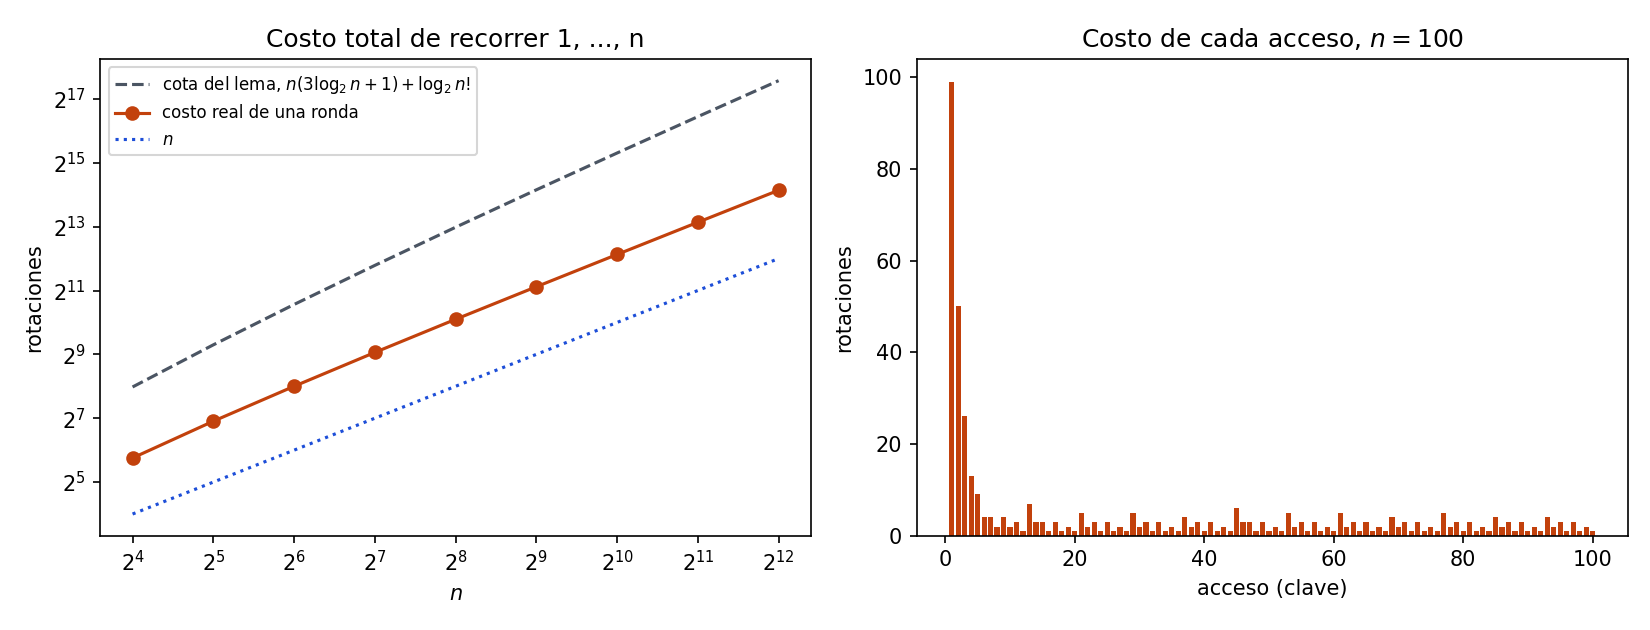

In [9]:
sizes = [2 ** e for e in range(4, 13)]
reales = []
for n in sizes:
    raiz, total = camino(n), 0
    for clave in range(1, n + 1):
        x = buscar(raiz, clave)
        total += max(splay(x), 1)
        raiz = x
    reales.append(total)

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2))
left.plot(sizes, [cota_total(n, n) for n in sizes], "--", color="#4b5563",
          label="cota del lema, $n(3\\log_2 n+1)+\\log_2 n!$")
left.plot(sizes, reales, "o-", color="#c2410c", label="costo real de una ronda")
left.plot(sizes, sizes, ":", color="#1d4ed8", label="$n$")
left.set_xscale("log", base=2)
left.set_yscale("log", base=2)
left.set_xlabel("$n$")
left.set_ylabel("rotaciones")
left.set_title("Costo total de recorrer 1, ..., n")
left.legend(fontsize=8)

raiz, por_acceso = camino(100), []
for clave in range(1, 101):
    x = buscar(raiz, clave)
    por_acceso.append(max(splay(x), 1))
    raiz = x
right.bar(range(1, 101), por_acceso, color="#c2410c")
right.set_xlabel("acceso (clave)")
right.set_ylabel("rotaciones")
right.set_title("Costo de cada acceso, $n=100$")
fig.tight_layout()
fig.savefig("ejercicio-13.png", dpi=150)
plt.close(fig)
print(f"{'n':>5} {'real':>7} {'real / n':>9} {'cota':>9} {'cota / real':>12}")
for n, r in zip(sizes, reales):
    print(f"{n:>5} {r:>7} {r / n:>9.2f} {cota_total(n, n):>9.0f} {cota_total(n, n) / r:>12.2f}")
display(Image("ejercicio-13.png"))